<a href="https://colab.research.google.com/github/rifahnanjiba02-arch/vision-language-composition/blob/main/scripts/MACCO_W1_CML_Visual_Patch_Noise_Controlled.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MACCO W1+CML — Masking vs Gaussian Visual-Patch Noise

We replace **visual patch *embedding* masks** inside the original MACCO ViT-B/32 encoder with Gaussian noise on the *same selected positions*. **Text masking stays unchanged**. We compare two independently trained arms—**mask control** and **visual-noise adaptation**—both starting from the original W1+CML checkpoint and matched random seeds.

**Sources:** Original W1+CML checkpoint from `rifahnanjiba2/MACCO-Finetuned`; reviewed hard negatives from [`results/cml_audit (1).csv`](https://github.com/rifahnanjiba02-arch/vision-language-composition/blob/main/results/cml_audit%20(1).csv); authors' [MACCO source + COCO annotation TSV](https://github.com/hiker-lw/MACCO); selected COCO 2014 images from [Hugging Face](https://huggingface.co/datasets/AbdoTW/COCO_2014).

**Primary question:** With the same training data, initial weights, training budget, W1+CML objective, and mask positions, does **visual-embedding Gaussian noise** produce a model that performs differently than the **masking control** on *held-out* clean/noisy image–text retrieval?

**Important limitations:** This is a small pilot, not a paper-level benchmark. Noise is applied **after ViT patch embedding**, not to JPEG pixels; model reconstruction still predicts image patches. The first 20 minibatches in each arm use identical mask-based warm-up because the source checkpoint is CLIP-only. The inherited MACCO contrastive objective was intentionally kept unchanged for a single-variable ablation, but it treats corrupted representations as competing views; inspect this in a follow-on loss ablation. Held-out COCO retrieval is a supplementary diagnostic, not ARO/SugarCrepe.

**Run sections top to bottom with a GPU runtime.** This notebook downloads only the requested COCO images; on the first run this may take time. Training both arms roughly doubles compute versus our earlier one-arm pilot.

## 1 · Install dependencies and fetch the authors’ MACCO source

In [1]:
%pip -q install "timm==1.0.15" ftfy regex "webdataset==0.2.111" braceexpand easydict PyYAML pytz wandb "huggingface_hub>=0.25,<2.0" "datasets>=3,<5" pandas matplotlib tqdm requests

In [2]:
from pathlib import Path
import os, sys, subprocess
import torch

ROOT = Path('/content/macco_w1_visual_noise')
AUTHOR_REPO = ROOT / 'MACCO'
ROOT.mkdir(parents=True, exist_ok=True)

if not (AUTHOR_REPO / '.git').exists():
    subprocess.run(['git','clone','--depth','1','--filter=blob:none','--no-checkout',
                    'https://github.com/hiker-lw/MACCO.git', str(AUTHOR_REPO)],check=True)
if not (AUTHOR_REPO / 'src/training/data_macco.py').is_file():
    subprocess.run(['git','-C',str(AUTHOR_REPO),'sparse-checkout','set','--no-cone',
                    '/src/', '/mscoco_object_relation_attribute_with_phrase_bbox.tsv'], check=True)
    subprocess.run(['git','-C',str(AUTHOR_REPO),'checkout','HEAD'], check=True)

ANNOTATIONS = AUTHOR_REPO/'mscoco_object_relation_attribute_with_phrase_bbox.tsv'
assert ANNOTATIONS.is_file(), 'Author MACCO TSV was not downloaded.'
assert torch.cuda.is_available(), 'Select a GPU runtime in Colab before running.'
sys.path.insert(0, str(AUTHOR_REPO/'src'))
print('GPU:', torch.cuda.get_device_name(0))
print('MACCO author commit:',subprocess.check_output(
    ['git','-C',str(AUTHOR_REPO),'rev-parse','HEAD'],text=True).strip())

GPU: Tesla T4
MACCO author commit: 97fbae1416e30eba84cc0b8209d9cb6bdedfe6ae


## 2 · Configuration: identical runs except visual corruption

In [3]:
#@title Visual-noise experiment settings
HF_REPO_ID = 'rifahnanjiba2/MACCO-Finetuned'
HF_CHECKPOINT_FILE = 'MACCO-W1-CML-ViT-B-32.pt'  # ORIGINAL, not text-noise-adapted
HF_REVISION = 'main'
GITHUB_REPO = 'rifahnanjiba02-arch/vision-language-composition'
GITHUB_REVISION = 'main'
GITHUB_AUDIT_PATH = 'results/cml_audit (1).csv'
HF_COCO_REPO = 'AbdoTW/COCO_2014'
OUTPUT_DIR = Path('/content/macco_w1_visual_noise_outputs')

SEED = 42
NUM_ROWS = 512
HOLDOUT_ROWS = 64       # Distinct COCO images excluded from the audited training images
EPOCHS = 3
BATCH_SIZE = 4
GRAD_ACCUM = 4
MAX_BATCHES_PER_EPOCH = 100
WARMUP_MASK_BATCHES = 20
NOISE_START = 0.15
NOISE_END = 1.0
EVAL_SIGMAS = (0.0, 0.25, 0.5, 1.0)
EVAL_BATCH_SIZE = 8
LR_CLIP = 5e-7
LR_HEADS = 1e-4
WEIGHT_DECAY = 0.01
W1_MCA = 1.0
W1_MIR = 0.2
W1_TEXT_RECON = 25.0
W1_IMAGE_RECON = 250.0
CML_WEIGHT = 1.0
CML_MARGIN = 0.05
ARMS = ('mask_control', 'visual_noise')  # Run both arms; set ('visual_noise',) for an initial smoke test
SAVE_ALL_EPOCHS = False  # Save full model per arm at FINAL epoch only

assert 0 <= NOISE_START <= NOISE_END and WARMUP_MASK_BATCHES >= 0
assert EPOCHS >= 1 and BATCH_SIZE >= 2 and GRAD_ACCUM >= 1
assert set(ARMS) <= {'mask_control','visual_noise'} and len(ARMS)>0
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('Outputs:', OUTPUT_DIR, '| arms:', ARMS)

Outputs: /content/macco_w1_visual_noise_outputs | arms: ('mask_control', 'visual_noise')


## 3 · Download the ORIGINAL W1+CML checkpoint from Hugging Face

In [5]:
from huggingface_hub import hf_hub_download

HF_TOKEN = None
try:
    from google.colab import userdata
    HF_TOKEN = userdata.get('HF_TOKEN')
except Exception:
    pass

CHECKPOINT = Path(hf_hub_download(
    repo_id = "rifahnanjiba2/MACCO-Finetuned",
    filename = "MACCO-W1-CML-ViT-B-32.pt",
    revision = "main",
    repo_type='model',
    token=HF_TOKEN,
))
print('Fine-tuned W1+CML checkpoint:', CHECKPOINT)
print('Size (MB):', round(CHECKPOINT.stat().st_size/1e6,1))

MACCO-W1-CML-ViT-B-32.pt: reconstructing file:   0%|          |  0.00B /  605MB            

MACCO-W1-CML-ViT-B-32.pt: downloading bytes:           |  0.00B            

Fine-tuned W1+CML checkpoint: /root/.cache/huggingface/hub/models--rifahnanjiba2--MACCO-Finetuned/snapshots/9f262ce601fe9efd856d9330387c958b5e4e598a/MACCO-W1-CML-ViT-B-32.pt
Size (MB): 605.2


## 4 · Download previously reviewed CML negatives directly from GitHub

In [6]:
from urllib.parse import quote
import pandas as pd
import requests

GH_URL = (f'https://raw.githubusercontent.com/{GITHUB_REPO}/'
          f'{quote(GITHUB_REVISION, safe="")}/'
          f'{quote(GITHUB_AUDIT_PATH, safe="/")}')
AUDIT_CSV = ROOT / 'cml_audit_reviewed.csv'
response = requests.get(GH_URL, timeout=90)
response.raise_for_status()
assert response.content.startswith(b'row_id,'), (
    'GitHub download did not return the expected audit CSV; check the URL.')
AUDIT_CSV.write_bytes(response.content)
audit = pd.read_csv(AUDIT_CSV, keep_default_na=False)
required = {'row_id','filepath','title','candidate_negative','approved'}
assert required.issubset(audit.columns), f'Missing audit columns: {required - set(audit.columns)}'
audit['approved'] = audit['approved'].astype(str).str.strip().str.lower().isin(
    ['true','1','yes','y'])
assert not audit.row_id.duplicated().any(), 'Duplicate audit row_id entries.'
assert not audit[['filepath','title']].duplicated().any(), 'Repeated file+caption in audit; inspect first.'
assert not (audit.approved & audit.candidate_negative.astype(str).str.strip().eq('')).any(), (
    'Approved row has no candidate negative.')
assert not (audit.approved & (audit.candidate_negative.str.strip() == audit.title.str.strip())).any(), (
    'An approved negative is identical to its positive caption.')
print('GitHub audit:', GH_URL)
print('Reviewed rows:', len(audit))
print('Approved negative captions:', int(audit.approved.sum()))
display(audit[['row_id','title','candidate_negative','approved']].head(5))

GitHub audit: https://raw.githubusercontent.com/rifahnanjiba02-arch/vision-language-composition/main/results/cml_audit%20%281%29.csv
Reviewed rows: 512
Approved negative captions: 107


,row_id,title,candidate_negative,approved
0,0,some street signs sitting by a wall,,False
1,1,Two surfers at the beach walking into the waves.,,False
2,2,Antique cars on the grass in front of an antiq...,Antique cars on the grass behind an antique tr...,True
3,3,A man in a blue shirt holding a white plate wi...,A man in a red shirt holding a white plate wit...,True
4,4,A group of men standing around a batting cage.,,False


## 5 · Rebuild reviewed training TSV and create distinct held-out COCO rows

The model’s original annotation fields are retained. The hold-out images are *excluded* from the 512 audited training images and do not use unreviewed negatives as CML targets. Hold-out retrieval uses the correct captions among distinct images.

In [7]:
import numpy as np

original = pd.read_csv(ANNOTATIONS, sep='\t')
original_cols = list(original.columns)
need_original = {'filepath','title','neg_caption','neg_image','object_list',
                 'relation_list','attribute_list','relation_phrase_list',
                 'attribute_phrase_list','relation_attribute_phrase_bbox_list'}
assert need_original.issubset(original_cols), 'Author annotation schema changed.'
selected_audit = audit.sort_values('row_id').head(NUM_ROWS).copy()
if original.duplicated(['filepath','title']).any():
    print('Note: removing repeated identical filepath/title rows from author annotations.')
    original = original.drop_duplicates(['filepath','title'], keep='first')
train_rows = selected_audit.merge(original, on=['filepath','title'],
                                  how='left', validate='one_to_one', sort=False)
assert train_rows['relation_attribute_phrase_bbox_list'].notna().all(), (
    'An audited filepath/title is absent from the authors TSV. Check both sources.')
train_rows = train_rows.sort_values('row_id').reset_index(drop=True)
# Non-approved rows receive the original title as their dummy negative, exactly as in W1+CML.
train_rows['neg_caption'] = [repr([neg if bool(ok) else pos])
    for ok,neg,pos in zip(train_rows.approved, train_rows.candidate_negative, train_rows.title)]
TRAIN_TSV = AUTHOR_REPO / 'cml_noise_train.tsv'
train_rows[original_cols].to_csv(TRAIN_TSV, sep='\t', index=False)
assert int(train_rows.approved.sum()) >= 10, 'Too few approved rows for a meaningful CML pilot.'
assert all(str(x).startswith('coco/train2014/') for x in train_rows.filepath), (
    'Expected authors COCO 2014 train2014 paths.')
print('Original author TSV rows:',len(original))
print('Matched original reviewed W1+CML rows:',len(train_rows))
print('Approved CML pairs in this training set:',int(train_rows.approved.sum()))
print('Output TSV:',TRAIN_TSV)
display(train_rows[['row_id','filepath','title','candidate_negative','approved']].head(4))

# Held-out COCO images (not in these W1+CML training rows), to evaluate retrieval.
remaining = original.loc[~original.filepath.isin(set(train_rows.filepath))].copy()
remaining = remaining.loc[remaining.relation_attribute_phrase_bbox_list.astype(str).str.strip() != '[]']
remaining = remaining.drop_duplicates('filepath').drop_duplicates('title')
assert len(remaining) >= HOLDOUT_ROWS, 'Not enough distinct held-out images.'
heldout = remaining.sample(HOLDOUT_ROWS, random_state=SEED).reset_index(drop=True)
# Do not use author-provided unreviewed hard captions in holdout.
heldout['neg_caption'] = [repr([v]) for v in heldout.title.astype(str)]
HOLDOUT_TSV = AUTHOR_REPO / 'visual_noise_holdout.tsv'
heldout[original_cols].to_csv(HOLDOUT_TSV,sep='\t',index=False)
assert not set(heldout.filepath).intersection(train_rows.filepath)
print('Held-out distinct images:',len(heldout), '| held-out TSV:',HOLDOUT_TSV)

Original author TSV rows: 109468
Matched original reviewed W1+CML rows: 512
Approved CML pairs in this training set: 107
Output TSV: /content/macco_w1_visual_noise/MACCO/cml_noise_train.tsv


,row_id,filepath,title,candidate_negative,approved
0,0,coco/train2014/COCO_train2014_000000052826.jpg,some street signs sitting by a wall,,False
1,1,coco/train2014/COCO_train2014_000000401846.jpg,Two surfers at the beach walking into the waves.,,False
2,2,coco/train2014/COCO_train2014_000000073215.jpg,Antique cars on the grass in front of an antiq...,Antique cars on the grass behind an antique tr...,True
3,3,coco/train2014/COCO_train2014_000000332204.jpg,A man in a blue shirt holding a white plate wi...,A man in a red shirt holding a white plate wit...,True


Held-out distinct images: 64 | held-out TSV: /content/macco_w1_visual_noise/MACCO/visual_noise_holdout.tsv


## 6 · Fetch only required COCO images from HF (train + holdout)

The earlier `ali-sh07` mirror includes only ~10,000 images. We use the fuller `AbdoTW/COCO_2014` mirror and do not disable SSL verification. Re-running reuses already downloaded valid local images.

In [8]:
#@title Retrieve only the COCO JPEGs required for both splits
from PIL import Image
from tqdm.auto import tqdm
from datasets import load_dataset
import pandas as pd
import io

data_dir = AUTHOR_REPO / 'datasets'
data_dir.mkdir(parents=True, exist_ok=True)
unique_paths = sorted(set(train_rows.filepath.astype(str)) | set(heldout.filepath.astype(str)))

def valid_image(path):
    if not path.is_file(): return False
    try:
        with Image.open(path) as img: img.verify()
        return True
    except Exception:
        path.unlink(missing_ok=True)
        return False

manifest = []
missing = {}
for rel in unique_paths:
    target = data_dir / rel
    if valid_image(target):
        manifest.append({'filepath':rel,'bytes':target.stat().st_size,'source':'local-cache'})
    else:
        missing[int(Path(rel).stem.split('_')[-1])] = rel
print('Cached:',len(manifest),'| Missing:',len(missing))

if missing:
    ds = load_dataset(HF_COCO_REPO,split='train',streaming=True,
                      filters=[('id','in',list(missing.keys()))],token=HF_TOKEN)
    for sample in tqdm(ds,desc='HF COCO selected images'):
        image_id = int(sample['id'])
        if image_id not in missing: continue
        rel = missing[image_id]
        target = data_dir / rel
        target.parent.mkdir(parents=True,exist_ok=True)
        im = sample['image']
        if isinstance(im,dict):
            im = Image.open(io.BytesIO(im['bytes'])) if im.get('bytes') is not None else Image.open(im['path'])
        with im: im.convert('RGB').save(target,format='JPEG',quality=95)
        assert valid_image(target),f'Invalid COCO image: {rel}'
        manifest.append({'filepath':rel,'bytes':target.stat().st_size,'source':'hf-full-coco'})
        del missing[image_id]
        if not missing: break

assert not missing, f'Images missing from HF mirror: {list(missing.values())[:8]} (total {len(missing)})'
manifest_csv=OUTPUT_DIR/'coco_hf_manifest.csv'
pd.DataFrame(manifest).sort_values('filepath').to_csv(manifest_csv,index=False)
print('Verified:',len(manifest),'images. Train:',len(train_rows),'Holdout:',len(heldout))

Cached: 0 | Missing: 576


README.md:   0%|          | 0.00/808 [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/28 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/28 [00:00<?, ?it/s]

HF COCO selected images: 0it [00:00, ?it/s]

AssertionError: Images missing from HF mirror: ['coco/val2014/COCO_val2014_000000069391.jpg', 'coco/val2014/COCO_val2014_000000083656.jpg', 'coco/val2014/COCO_val2014_000000087230.jpg', 'coco/val2014/COCO_val2014_000000096048.jpg', 'coco/val2014/COCO_val2014_000000103232.jpg', 'coco/val2014/COCO_val2014_000000131539.jpg', 'coco/val2014/COCO_val2014_000000131612.jpg', 'coco/val2014/COCO_val2014_000000141755.jpg'] (total 21)

In [9]:

#@title FIX: Retrieve missing COCO validation images

from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
from datasets import load_dataset, get_dataset_split_names
import pandas as pd
import io

HF_FULL_COCO = "AbdoTW/COCO_2014"
data_dir = AUTHOR_REPO / "datasets"

unique_paths = sorted(
    set(train_rows.filepath.astype(str)) |
    set(heldout.filepath.astype(str))
)

def valid_image(path):
    if not path.is_file():
        return False
    try:
        with Image.open(path) as im:
            im.verify()
        return True
    except Exception:
        path.unlink(missing_ok=True)
        return False

# Reuse all successfully downloaded images
manifest = []
missing = {}

for rel in unique_paths:
    target = data_dir / rel

    if valid_image(target):
        manifest.append({
            "filepath": rel,
            "bytes": target.stat().st_size,
            "source": "local-cache"
        })
    else:
        image_id = int(Path(rel).stem.split("_")[-1])
        missing.setdefault(image_id, []).append(rel)

print("Already downloaded:", len(manifest))
print("Remaining:", sum(map(len, missing.values())))

# Search validation/test splits, not the train split again
available_splits = get_dataset_split_names(HF_FULL_COCO)
print("Available splits:", available_splits)

candidate_splits = [
    s for s in available_splits if s != "train"
]

for split in candidate_splits:
    if not missing:
        break

    print(f"\nSearching split: {split}")

    ds = load_dataset(
        HF_FULL_COCO,
        split=split,
        streaming=True,
        filters=[("id", "in", sorted(missing.keys()))],
        token=HF_TOKEN
    )

    for sample in tqdm(ds, desc=f"COCO {split}"):
        image_id = int(sample["id"])

        if image_id not in missing:
            continue

        # Check exact filename to avoid train/val ID confusion
        filename = Path(sample.get("coco_url", "")).name

        matched = [
            rel for rel in missing[image_id]
            if Path(rel).name == filename
        ]

        if not matched:
            continue

        rel = matched[0]
        target = data_dir / rel
        target.parent.mkdir(parents=True, exist_ok=True)

        im = sample["image"]

        if isinstance(im, dict):
            if im.get("bytes") is not None:
                im = Image.open(io.BytesIO(im["bytes"]))
            else:
                im = Image.open(im["path"])

        with im:
            im.convert("RGB").save(
                target, format="JPEG", quality=95
            )

        assert valid_image(target), f"Invalid JPEG: {rel}"

        manifest.append({
            "filepath": rel,
            "bytes": target.stat().st_size,
            "source": f"hf-{split}"
        })

        missing[image_id].remove(rel)
        if not missing[image_id]:
            del missing[image_id]

        if not missing:
            break

remaining = sum(map(len, missing.values()))

if remaining:
    raise RuntimeError(
        f"{remaining} images still missing: "
        f"{list(missing.items())[:5]}"
    )

manifest_csv = OUTPUT_DIR / "coco_hf_manifest.csv"

pd.DataFrame(manifest).sort_values(
    "filepath"
).to_csv(manifest_csv, index=False)

print("\nSUCCESS!")
print("Verified images:", len(manifest))
print("Training images:", len(train_rows))
print("Held-out images:", len(heldout))
print("Manifest:", manifest_csv)


Already downloaded: 555
Remaining: 21


Resolving data files:   0%|          | 0/28 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/28 [00:00<?, ?it/s]

Available splits: ['train', 'validation', 'test']

Searching split: validation


Resolving data files:   0%|          | 0/28 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/28 [00:00<?, ?it/s]

COCO validation: 0it [00:00, ?it/s]


SUCCESS!
Verified images: 576
Training images: 512
Held-out images: 64
Manifest: /content/macco_w1_visual_noise_outputs/coco_hf_manifest.csv


## 7 · Patch ONLY visual patch corruption in original MACCO code

The clean ViT branch remains untouched. In the second (corrupted) branch, **image masks are replaced by noise at precisely those patch indices**. The class token is never corrupted. Text encoding and text masking remain original MACCO. This patch affects only the local Colab clone.

In [10]:
#@title Add image mask/noise toggle without changing the text encoder
model_path = AUTHOR_REPO/'src/open_clip_code/MACCO_variant/MACCO_text_image.py'
src = model_path.read_text()
# Fix the original project's method binding for current Python, as in the earlier notebook.
for method, target in [('clip_encode_text','self.CLIP'),('clip_encode_image','self.CLIP'),
                       ('clip_vit_forward','self.CLIP.visual'),('clip_forward','self.CLIP')]:
    original_bind=f'self.{method}.__get__({target})'
    fixed_bind=f'type(self).{method}.__get__({target}, type({target}))'
    if original_bind in src: src=src.replace(original_bind,fixed_bind,1)
    else: assert fixed_bind in src, f'Method binding not found: {method}'

needle = '        x_full_mask = x_full_mask * (~key_mask[:, :, None]) + ' + chr(92) + '\n' + \
         '                img_mask_token[None, None, :] * key_mask[:, :, None]'
replacement = '''        # W1_CML_VISUAL_NOISE_PATCH: clean half unchanged, selected patches only.
        mode = getattr(self, 'image_corruption_mode', 'mask')
        if mode == 'noise':
            # Use clean visual patch embedding scale; never perturb class-token position.
            scale = x[:, 1:].detach().float().std().clamp_min(1e-6).to(x.dtype)
            sigma = float(getattr(self, 'image_noise_strength', 0.0))
            key_mask[:, 0] = False
            x_full_mask = x_full_mask + (sigma * scale * torch.randn_like(x_full_mask)) * key_mask.unsqueeze(-1)
        elif mode == 'mask':
            x_full_mask = (
                x_full_mask * (~key_mask[:, :, None])
                + img_mask_token[None, None, :] * key_mask[:, :, None]
            )
        else:
            raise ValueError(f'Unknown image corruption: {mode}')'''
if 'W1_CML_VISUAL_NOISE_PATCH' not in src:
    assert src.count(needle)==1, 'Expected one original image mask line. Inspect upstream change.'
    src=src.replace(needle,replacement,1)
model_path.write_text(src)
compile(src,str(model_path),'exec')
print('Visual-patch mask/noise toggle installed. Original text masking untouched.')

Visual-patch mask/noise toggle installed. Original text masking untouched.


## 8 · Build matched W1+CML models from identical initial conditions

The original export is CLIP-only, so the MACCO prediction heads are initialized afresh. **Each experiment arm starts from the same checkpoint and random seed**, with identical 20-batch masked warm-up. No text-noise checkpoint is used.

In [11]:
import math, random, gc, json, copy
import torch.nn.functional as F
import yaml
from torch.utils.data import DataLoader
from open_clip_code import create_model_and_transforms, tokenize
from open_clip_code.MACCO_variant.MACCO_text_image import MACCO_CLIP_text_image
from open_clip_code.loss_fn.MACCO_CLIP_loss_text_image_raw_space import (
    macco_clip_loss_text_image, compute_contrast_loss)
from training.data_macco import get_data, CsvDataset_mask_text_image
from training.utils import create_transform_with_tracking
from training.params import parse_args

DEVICE=torch.device('cuda')
_saved_argv=sys.argv[:]
try:
    sys.argv=[sys.argv[0],'--model','ViT-B-32']
    args=parse_args()
finally:
    sys.argv=_saved_argv
for k,v in yaml.safe_load((AUTHOR_REPO/'src/config/MACCO_CLIP.yaml').read_text()).items():
    setattr(args,k,v)
args.model='ViT-B-32'
args.train_data=TRAIN_TSV.name
args.dataset_type='csv'
args.batch_size=BATCH_SIZE
args.workers=2
args.mask_text_image=True
args.mask_image=False; args.mask_text=False
args.add_neg_sample=False
args.random_mask_text=False; args.random_mask_image=False
args.random_rectangular_mask_prob=0.0  # Grounded boxes only, same for both arms
args.distributed=False; args.world_size=1
args.imagenet_val=None; args.imagenet_v2=None; args.val_data=None
args.contrast_loss_w=W1_MCA
args.intra_modal_contrast_loss_w=W1_MIR
args.mask_text_loss_w=W1_TEXT_RECON
args.mask_image_loss_w=W1_IMAGE_RECON
args.cml_weight=CML_WEIGHT
args.cml_margin=CML_MARGIN

def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

raw=torch.load(CHECKPOINT,map_location='cpu',weights_only=True)
orig_sd=raw.get('state_dict',raw) if isinstance(raw,dict) else raw
orig_sd={k.removeprefix('module.'):v for k,v in orig_sd.items()}
full_input=any(k.startswith('CLIP.') for k in orig_sd)
if full_input:
    native_path=ROOT/'extracted_original_clip.pt'
    torch.save({k.removeprefix('CLIP.'):v for k,v in orig_sd.items() if k.startswith('CLIP.')}, native_path)
else:
    native_path=CHECKPOINT
# Get evaluation transforms once. Re-create the models for each arm below.
def new_model():
    global val_preprocess
    seed_all(SEED+7)  # identical MACCO prediction heads and mask tokens in both arms
    clip_model,_,val_preprocess=create_model_and_transforms(
        'ViT-B-32',pretrained=str(native_path),device='cpu',precision='fp32')
    m=MACCO_CLIP_text_image(clip_model,args)
    if full_input:
        m.load_state_dict(orig_sd,strict=True)
    m=m.to(DEVICE)
    m.CLIP.visual.image_corruption_mode='mask'
    m.CLIP.visual.image_noise_strength=0.0
    return m
# Small temporary instance to establish model patch size / transforms.
model=new_model()
criterion=macco_clip_loss_text_image(args)
print('Checkpoint:', 'full MACCO' if full_input else 'CLIP-only W1+CML')
print('Patch size:',model.patch_size,'| Original loss weights:',
      (W1_MCA,W1_MIR,W1_TEXT_RECON,W1_IMAGE_RECON,CML_WEIGHT,CML_MARGIN))

/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:48: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


Checkpoint: CLIP-only W1+CML
Patch size: 32 | Original loss weights: (1.0, 0.2, 25.0, 250.0, 1.0, 0.05)


## 9 · Load authors’ original training flags and inspect selected regions

We keep scene-graph relation/attribute token flags and aligned visual bounding-box patch flags. The visual plot highlights *which patch embeddings* will be corrupted. It is not a pixel-noise simulation.

In [12]:
train_preprocess, get_transform_params=create_transform_with_tracking(image_size=224)
training_data=get_data(args,(train_preprocess,val_preprocess),epoch=0,
                       get_transform_params=get_transform_params)
train_loader=training_data['train'].dataloader
train_dataset=train_loader.dataset
preview=next(iter(train_loader))
imgs,toks,neg,txt_flags,obj_flags,img_flags=preview
assert toks.shape==txt_flags.shape
assert img_flags.shape[1]==50 and not img_flags[:,0].any(), 'Unexpected class-token mask'
print('Rows:',len(train_dataset),'| batches/epoch:',len(train_loader))
print('Batch images:',tuple(imgs.shape),'| selected visual patches:',int(img_flags[:,1:].sum()))
print('Visual patch fraction:',round(img_flags[:,1:].float().mean().item(),4))
print('Text concept tokens:',int(txt_flags.sum()))

Rows: 512 | batches/epoch: 128
Batch images: (4, 3, 224, 224) | selected visual patches: 91
Visual patch fraction: 0.4643
Text concept tokens: 13


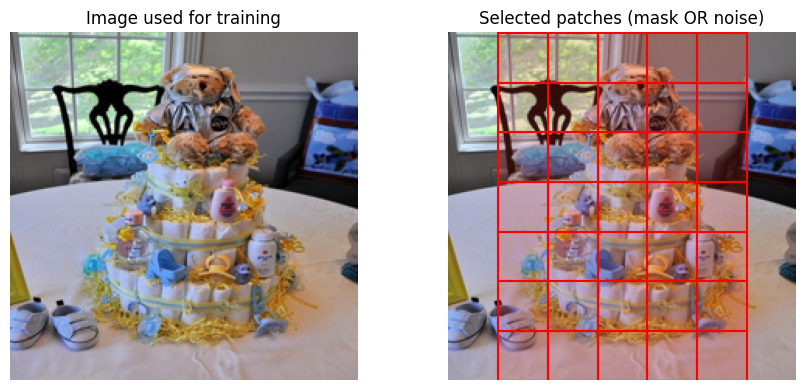

In [13]:
#@title Visual sanity check: highlighted selected visual regions
import matplotlib.pyplot as plt
norm_mean=torch.tensor([0.48145466,0.4578275,0.40821073]).view(3,1,1)
norm_std=torch.tensor([0.26862954,0.26130258,0.27577711]).view(3,1,1)
fig,ax=plt.subplots(1,2,figsize=(9,4))
show_idx=int(img_flags[:,1:].sum(dim=1).argmax().item())
img=((imgs[show_idx].cpu()*norm_std)+norm_mean).clamp(0,1).permute(1,2,0).numpy()
ax[0].imshow(img);ax[0].set_title('Image used for training');ax[0].axis('off')
ax[1].imshow(img)
from matplotlib.patches import Rectangle
for i,flag in enumerate(img_flags[show_idx,1:].tolist()):
    if flag:
        row,col=divmod(i,7)
        ax[1].add_patch(Rectangle((col*32,row*32),32,32,
                                  facecolor=(1,0.25,0.2,0.18),edgecolor='red',linewidth=1.5))
ax[1].set_title('Selected patches (mask OR noise)');ax[1].axis('off')
plt.tight_layout();plt.savefig(OUTPUT_DIR/'selected_visual_patches.png',dpi=150)
plt.show()

## 10 · W1+CML objective: unchanged across both arms

The same original MACCO contrastive, intra-modal, text-reconstruction and image-reconstruction losses are used in BOTH runs, plus approved-negative CML. No loss is redesigned here. Unlike our text-noise experiment, we **do not replace** the contrastive component for noise batches; this keeps the contrastive objective strictly identical, but the original negative-view assumption is a known limitation to test later.

In [14]:
def objective_w1_cml(m,output,texts,negative_texts):
    losses=criterion(output)
    empty_mask=torch.zeros_like(negative_texts,dtype=torch.bool)
    neg_raw,*_=m.CLIP.encode_text(negative_texts,empty_mask,m.text_mask_token)
    neg=F.normalize(neg_raw,dim=-1)
    img_embed=output['img_feat_cls_token']
    pos=output['text_feat_cls_token']
    pos_cos=(img_embed*pos).sum(-1)
    neg_cos=(img_embed*neg).sum(-1)
    approved=(negative_texts!=texts).any(dim=1)
    hinge=F.relu(CML_MARGIN+neg_cos-pos_cos)
    cml=hinge[approved].mean() if approved.any() else hinge.sum()*0.0
    losses['cml_loss']=cml
    losses['approved_in_batch']=approved.sum().detach()
    losses['total_loss']=(W1_MCA*losses['contrast_loss']+
                          W1_MIR*losses['intra_modal_contrast_loss']+
                          W1_TEXT_RECON*losses['mask_loss_text']+
                          W1_IMAGE_RECON*losses['mask_loss_image']+
                          CML_WEIGHT*cml)
    return losses

# Verify mask path and visual noise path work before expensive training.
model.eval()
a,b,c,tf,_,im=preview
sl=slice(0,2)
a,b,c,tf,im=[v[sl].to(DEVICE) for v in (a,b,c,tf,im)]
for mode,sigma in [('mask',0.0),('noise',0.15)]:
    model.CLIP.visual.image_corruption_mode=mode
    model.CLIP.visual.image_noise_strength=sigma
    with torch.no_grad(),torch.autocast('cuda',dtype=torch.float16):
        out=model(a,b,im,tf)
        loss=objective_w1_cml(model,out,b,c)
    assert torch.isfinite(loss['total_loss']),f'Nonfinite loss in {mode}'
    print(mode, 'sigma',sigma, 'loss',round(loss['total_loss'].item(),3),
          'patches',int(im[:,1:].sum()))
del model
import gc
gc.collect();torch.cuda.empty_cache()

mask sigma 0.0 loss 522.433 patches 47
noise sigma 0.15 loss 522.237 patches 47


## 11 · Prepare fixed, held-out retrieval test tensors

Held-out images were excluded from the 512 W1+CML adaptation rows. To ensure **identical evaluation data** for the two arms and each sigma, we materialize the transformed held-out examples *once* with a frozen random seed. We evaluate image→caption retrieval over all held-out candidates, reporting R@1 and mean paired-image/caption cosine.

In [15]:
# Use original author tracked transform so bounding-box patch flags match the crop.
seed_all(SEED+811)
eval_transforms,eval_tracking=create_transform_with_tracking(image_size=224)
eval_dataset=CsvDataset_mask_text_image(
    args,HOLDOUT_TSV.name,eval_transforms,eval_tracking,
    img_key=args.csv_img_key,caption_key=args.csv_caption_key,sep=args.csv_separator)
# Cache tensors (64 * 3 * 224 * 224 ~ 39 MB), removing stochastic crop differences.
eval_items=[eval_dataset[i] for i in range(len(eval_dataset))]
eval_batches=[]
for i in range(0,len(eval_items),EVAL_BATCH_SIZE):
    batch=eval_items[i:i+EVAL_BATCH_SIZE]
    eval_batches.append(tuple(torch.stack([row[j] for row in batch])
                              for j in range(len(batch[0]))))
print('Held-out evaluation samples:',len(eval_items))
print('Selected patch rate:',round(float(torch.cat([b[5][:,1:] for b in eval_batches]).float().mean()),4))
assert len(eval_items)==HOLDOUT_ROWS

Held-out evaluation samples: 64
Selected patch rate: 0.611


In [16]:
@torch.no_grad()
def evaluate_common_gaussian(m,arm,when):
    # Every arm is tested on exactly the same Gaussian image-patch noise levels.
    m.eval()
    records=[]
    for sigma in EVAL_SIGMAS:
        seed_all(SEED+911+int(sigma*1000))
        m.CLIP.visual.image_corruption_mode='noise'
        m.CLIP.visual.image_noise_strength=sigma
        all_img=[]; all_txt=[]; mse_list=[]
        for x,t,negative,tf,of,im in eval_batches:
            x,t,im=x.to(DEVICE),t.to(DEVICE),im.to(DEVICE)
            no_text_corruption=torch.zeros_like(t,dtype=torch.bool)
            with torch.autocast('cuda',dtype=torch.float16):
                clean_img,_,corrupt_img,_=m.CLIP.encode_image(x,im,m.img_mask_token)
                txt,*_=m.CLIP.encode_text(t,no_text_corruption,m.text_mask_token)
            all_img.append(F.normalize(corrupt_img.float(),dim=-1).cpu())
            all_txt.append(F.normalize(txt.float(),dim=-1).cpu())
        im_feats=torch.cat(all_img)
        txt_feats=torch.cat(all_txt)
        sim=im_feats@txt_feats.T
        diag=sim.diag()
        rank=(sim.argmax(dim=1)==torch.arange(sim.shape[0])).float().mean().item()
        records.append({'arm':arm,'stage':when,'sigma':sigma,
                        'heldout_images':len(eval_items),'image_to_text_R_at_1':rank,
                        'paired_cosine':float(diag.mean().item())})
    m.CLIP.visual.image_corruption_mode='mask'
    m.CLIP.visual.image_noise_strength=0.0
    return records

In [17]:
#@title Additional held-out image-patch reconstruction test (small, fixed subset)
RECON_ROWS = 16    # Keep this small; reconstruction heads use more GPU memory than retrieval.

@torch.no_grad()
def evaluate_image_reconstruction(m,arm,when):
    m.eval()
    results=[]
    for sigma in EVAL_SIGMAS:
        seed_all(SEED+1211+int(sigma*1000))
        m.CLIP.visual.image_corruption_mode='noise'
        m.CLIP.visual.image_noise_strength=float(sigma)
        losses=[];valid=0
        # 16 cached held-out examples, in batches no larger than training BATCH_SIZE.
        eval_subset=eval_items[:RECON_ROWS]
        for off in range(0,len(eval_subset),BATCH_SIZE):
            chunk=eval_subset[off:off+BATCH_SIZE]
            xs,ts,tflags,imflags=(torch.stack([row[j] for row in chunk]).to(DEVICE)
                                    for j in (0,1,3,5))
            with torch.autocast('cuda',dtype=torch.float16):
                output=m(xs,ts,imflags,tflags)
                # Only selected image patch targets count, same as original MACCO.
                patch_mse=criterion._compute_mask_loss_image(
                    output['pred_image'],output['target_image'],output['image_mask_index'],32)
            selected_images=int((imflags[:,1:].sum(dim=1)>0).sum())
            if selected_images:
                losses.append((float(patch_mse.item()),selected_images))
                valid+=selected_images
        mse=(sum(val*n for val,n in losses)/valid) if valid else float('nan')
        results.append({'arm':arm,'stage':when,'sigma':sigma,
                        'heldout_images':len(eval_subset),'images_with_selected_patches':valid,
                        'selected_patch_reconstruction_MSE':mse})
    m.CLIP.visual.image_corruption_mode='mask'
    m.CLIP.visual.image_noise_strength=0.0
    return results

## 12 · Train two arms with the same initial weights, warm-up, W1+CML losses, and schedule

The **mask_control** keeps original visual masking after warm-up. The **visual_noise** arm replaces the same selected visual patches with progressive Gaussian noise after warm-up. Per-minibatch logs save the actual mode and sigma, avoiding the misleading “last batch sigma = 0” from our previous experiment. Both arms are evaluated using the **same** Gaussian corruption at held-out test time.

In [18]:
#@title Run the controlled two-arm fine-tuning experiment
from tqdm.auto import tqdm
import time

steps_per_epoch=min(len(train_loader),MAX_BATCHES_PER_EPOCH or len(train_loader))
total_steps=steps_per_epoch*EPOCHS
assert WARMUP_MASK_BATCHES < total_steps

def mode_sigma(arm,step):
    if arm=='mask_control' or step < WARMUP_MASK_BATCHES:
        return 'mask',0.0
    frac=(step-WARMUP_MASK_BATCHES)/max(1,total_steps-WARMUP_MASK_BATCHES-1)
    return 'noise',NOISE_START+(NOISE_END-NOISE_START)*min(1.0,frac)

all_history=[]
all_steps=[]
all_evals=[]
all_recon=[]
for arm in ARMS:
    print('\n'+'='*60+'\nTraining ARM:',arm)
    m=new_model()
    before_eval=evaluate_common_gaussian(m,arm,'before')
    all_evals.extend(before_eval)
    all_recon.extend(evaluate_image_reconstruction(m,arm,'before'))
    model_clip_params=[p for p in m.CLIP.parameters() if p.requires_grad]
    ids={id(p) for p in model_clip_params}
    head_params=[p for p in m.parameters() if p.requires_grad and id(p) not in ids]
    optim=torch.optim.AdamW([
        {'params':model_clip_params,'lr':LR_CLIP},
        {'params':head_params,'lr':LR_HEADS}],weight_decay=WEIGHT_DECAY)
    scaler=torch.amp.GradScaler('cuda',enabled=True)
    seed_all(SEED+111)  # same shuffling/crop/noise RNG reset for each arm
    global_step=0
    arm_history=[]
    for epoch in range(1,EPOCHS+1):
        m.train()
        optim.zero_grad(set_to_none=True)
        totals={k:0.0 for k in ['total_loss','contrast_loss','intra_modal_contrast_loss',
                                'mask_loss_text','mask_loss_image','cml_loss']}
        mode_counts={'mask':0,'noise':0};sigmas=[];approved_uses=0
        flagged_patch_total=0;patch_positions_total=0;optimizer_steps=0
        iterator=iter(train_loader)
        for batch_idx in tqdm(range(steps_per_epoch),desc=f'{arm} epoch {epoch}/{EPOCHS}'):
            batch=next(iterator)
            x,t,neg,tf,of,im=[v.to(DEVICE,non_blocking=True) for v in batch]
            assert not im[:,0].any(), 'Class token is not supposed to be masked'
            mode,sigma=mode_sigma(arm,global_step)
            m.CLIP.visual.image_corruption_mode=mode
            m.CLIP.visual.image_noise_strength=sigma
            with torch.autocast('cuda',dtype=torch.float16):
                output=m(x,t,im,tf)
                losses=objective_w1_cml(m,output,t,neg)
                # Scale last partial accumulation window correctly.
                window_start=(batch_idx//GRAD_ACCUM)*GRAD_ACCUM
                window_size=min(GRAD_ACCUM,steps_per_epoch-window_start)
                backprop_loss=losses['total_loss']/window_size
            assert torch.isfinite(backprop_loss),f'Nonfinite loss: {arm}, epoch {epoch}, batch {batch_idx}'
            scaler.scale(backprop_loss).backward()
            if (batch_idx+1)%GRAD_ACCUM==0 or batch_idx+1==steps_per_epoch:
                scaler.unscale_(optim)
                torch.nn.utils.clip_grad_norm_(m.parameters(),1.0)
                scaler.step(optim);scaler.update();optim.zero_grad(set_to_none=True)
                with torch.no_grad():m.CLIP.logit_scale.clamp_(0,math.log(100))
                optimizer_steps+=1
            mode_counts[mode]+=1
            if mode=='noise':sigmas.append(float(sigma))
            approved_uses+=int(losses['approved_in_batch'])
            flagged_patch_total+=int(im[:,1:].sum())
            patch_positions_total+=im[:,1:].numel()
            row={'arm':arm,'epoch':epoch,'global_batch':global_step+1,
                 'mode':mode,'sigma':sigma,'selected_visual_patches':int(im[:,1:].sum()),
                 'image_patch_fraction':float(im[:,1:].float().mean()),
                 'approved_pairs_used':int(losses['approved_in_batch'])}
            for k in totals:
                val=float(losses[k].detach().cpu())
                totals[k]+=val
                row[k]=val
            all_steps.append(row)
            global_step+=1
        record={'arm':arm,'epoch':epoch,'batches':steps_per_epoch,
                'optimizer_updates':optimizer_steps,
                'mask_batches':mode_counts['mask'],'noise_batches':mode_counts['noise'],
                'noise_sigma_mean':float(np.mean(sigmas)) if sigmas else 0.0,
                'noise_sigma_min':float(min(sigmas)) if sigmas else 0.0,
                'noise_sigma_max':float(max(sigmas)) if sigmas else 0.0,
                'approved_pair_uses':approved_uses,
                'mean_selected_patch_fraction':flagged_patch_total/max(1,patch_positions_total),
                **{k:v/steps_per_epoch for k,v in totals.items()}}
        arm_history.append(record)
        all_history.append(record)
        display(pd.DataFrame([record]))
        if SAVE_ALL_EPOCHS or epoch==EPOCHS:
            arm_dir=OUTPUT_DIR/arm
            arm_dir.mkdir(parents=True,exist_ok=True)
            ckpt=arm_dir/f'{arm}_full_epoch_{epoch}.pt'
            torch.save({'epoch':epoch,'arm':arm,'state_dict':m.state_dict(),
                        'history':arm_history,
                        'settings':{'starting_hf':f'{HF_REPO_ID}/{HF_CHECKPOINT_FILE}',
                                    'same_loss_both_arms':True,'noise_start':NOISE_START,
                                    'noise_end':NOISE_END,'seed':SEED}},ckpt)
            print('Saved full checkpoint:',ckpt)
    clip_path=OUTPUT_DIR/arm/f'MACCO-W1-CML-{arm}-ViT-B-32.pt'
    torch.save(m.CLIP.state_dict(),clip_path)
    print('Saved CLIP-only:',clip_path)
    after_eval=evaluate_common_gaussian(m,arm,'after')
    all_evals.extend(after_eval)
    all_recon.extend(evaluate_image_reconstruction(m,arm,'after'))
    pd.DataFrame(all_history).to_csv(OUTPUT_DIR/'training_history_by_arm.csv',index=False)
    pd.DataFrame(all_steps).to_csv(OUTPUT_DIR/'training_batches.csv',index=False)
    pd.DataFrame(all_evals).to_csv(OUTPUT_DIR/'heldout_gaussian_retrieval.csv',index=False)
    pd.DataFrame(all_recon).to_csv(OUTPUT_DIR/'heldout_reconstruction.csv',index=False)
    del m,optim,scaler,model_clip_params,head_params
    gc.collect();torch.cuda.empty_cache()
print('\nTraining complete. Summary files:')
for f in ('training_history_by_arm.csv','training_batches.csv','heldout_gaussian_retrieval.csv','heldout_reconstruction.csv'):
    print(OUTPUT_DIR/f)


Training ARM: mask_control


mask_control epoch 1/3:   0%|          | 0/100 [00:00<?, ?it/s]

,arm,epoch,batches,optimizer_updates,mask_batches,noise_batches,noise_sigma_mean,noise_sigma_min,noise_sigma_max,approved_pair_uses,mean_selected_patch_fraction,total_loss,contrast_loss,intra_modal_contrast_loss,mask_loss_text,mask_loss_image,cml_loss
0,mask_control,1,100,25,100,0,0.0,0.0,0.0,83,0.542704,504.621162,0.297783,0.22147,10.213256,0.995699,0.023013


mask_control epoch 2/3:   0%|          | 0/100 [00:00<?, ?it/s]

,arm,epoch,batches,optimizer_updates,mask_batches,noise_batches,noise_sigma_mean,noise_sigma_min,noise_sigma_max,approved_pair_uses,mean_selected_patch_fraction,total_loss,contrast_loss,intra_modal_contrast_loss,mask_loss_text,mask_loss_image,cml_loss
0,mask_control,2,100,25,100,0,0.0,0.0,0.0,78,0.526122,459.373899,0.220066,0.195074,8.570842,0.979284,0.022658


...

visual_noise epoch 2/3:   0%|          | 0/100 [00:00<?, ?it/s]

,arm,epoch,batches,optimizer_updates,mask_batches,noise_batches,noise_sigma_mean,noise_sigma_min,noise_sigma_max,approved_pair_uses,mean_selected_patch_fraction,total_loss,contrast_loss,intra_modal_contrast_loss,mask_loss_text,mask_loss_image,cml_loss
0,visual_noise,2,100,25,0,100,0.544534,0.393728,0.695341,78,0.526122,459.171987,0.215483,0.223006,8.57589,0.977968,0.022621


visual_noise epoch 3/3:   0%|          | 0/100 [00:00<?, ?it/s]

,arm,epoch,batches,optimizer_updates,mask_batches,noise_batches,noise_sigma_mean,noise_sigma_min,noise_sigma_max,approved_pair_uses,mean_selected_patch_fraction,total_loss,contrast_loss,intra_modal_contrast_loss,mask_loss_text,mask_loss_image,cml_loss
0,visual_noise,3,100,25,0,100,0.849194,0.698387,1.0,80,0.544286,422.1348,0.289547,0.357735,7.21805,0.965201,0.022202


Saved full checkpoint: /content/macco_w1_visual_noise_outputs/visual_noise/visual_noise_full_epoch_3.pt
Saved CLIP-only: /content/macco_w1_visual_noise_outputs/visual_noise/MACCO-W1-CML-visual_noise-ViT-B-32.pt

Training complete. Summary files:
/content/macco_w1_visual_noise_outputs/training_history_by_arm.csv
/content/macco_w1_visual_noise_outputs/training_batches.csv
/content/macco_w1_visual_noise_outputs/heldout_gaussian_retrieval.csv
/content/macco_w1_visual_noise_outputs/heldout_reconstruction.csv


## 13 · Compare clean and noise performance on the SAME held-out inputs

The metric is **image→caption retrieval R@1 over all held-out captions**, not ARO Attribute. Compare before→after within each arm, then compare the two trained arms at the same noise sigma. `sigma=0` tests clean patch embeddings; larger sigma tests noisy embeddings on annotation-selected regions.

stage               after  before  change_pp
arm          sigma                          
mask_control 0.00   92.19   92.19       0.00
             0.25   54.69   54.69       0.00
             0.50   37.50   37.50       0.00
             1.00   31.25   26.56       4.69
visual_noise 0.00   90.62   92.19      -1.56
             0.25   67.19   54.69      12.50
             0.50   48.44   37.50      10.94
             1.00   28.12   26.56       1.56

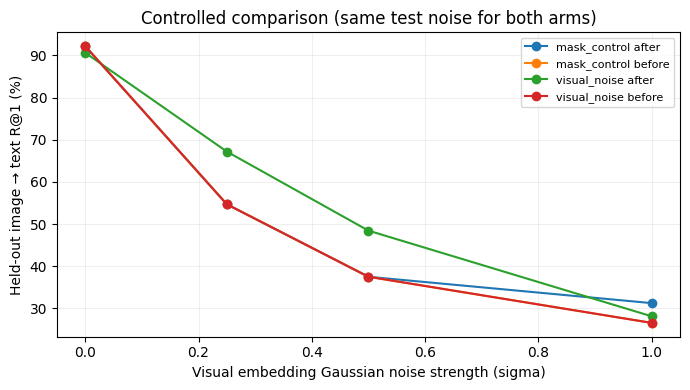

,arm,epoch,mask_batches,noise_batches,noise_sigma_mean,noise_sigma_max,total_loss,mask_loss_text,mask_loss_image,cml_loss
0,mask_control,1,100,0,0.0000,0.0000,504.6212,10.2133,0.9957,0.0230
1,mask_control,2,100,0,0.0000,0.0000,459.3739,8.5708,0.9793,0.0227
2,mask_control,3,100,0,0.0000,0.0000,422.1518,7.2071,0.9667,0.0222
3,visual_noise,1,20,80,0.2703,0.3907,504.5178,10.2131,0.9955,0.0230
4,visual_noise,2,0,100,0.5445,0.6953,459.1720,8.5759,0.9780,0.0226
5,visual_noise,3,0,100,0.8492,1.0000,422.1348,7.2180,0.9652,0.0222


Held-out selected-patch reconstruction MSE (lower is better):


stage                after  before
arm          sigma                
mask_control 0.00   0.9376  1.0004
             0.25   0.9377  1.0004
             0.50   0.9365  1.0004
             1.00   0.9364  1.0004
visual_noise 0.00   0.9373  1.0004
             0.25   0.9389  1.0004
             0.50   0.9364  1.0004
             1.00   0.9354  1.0004

In [19]:
#@title Tables, curves, and deltas for matched evaluation
result_df=pd.read_csv(OUTPUT_DIR/'heldout_gaussian_retrieval.csv')
result_df['R_at_1_percent']=100*result_df['image_to_text_R_at_1']
summary=result_df.pivot_table(index=['arm','sigma'],columns='stage',values='R_at_1_percent')
if {'before','after'} <= set(summary.columns):
    summary['change_pp']=summary['after']-summary['before']
display(summary.round(2))
summary.to_csv(OUTPUT_DIR/'heldout_retrieval_comparison.csv')

fig,ax=plt.subplots(figsize=(7,4))
for (arm,stage),grp in result_df.groupby(['arm','stage']):
    grp=grp.sort_values('sigma')
    ax.plot(grp.sigma,grp.R_at_1_percent,marker='o',label=f'{arm} {stage}')
ax.set_xlabel('Visual embedding Gaussian noise strength (sigma)')
ax.set_ylabel('Held-out image → text R@1 (%)')
ax.set_title('Controlled comparison (same test noise for both arms)')
ax.legend(fontsize=8);ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(OUTPUT_DIR/'heldout_robustness_curves.png',dpi=150)
plt.show()

hist_df=pd.read_csv(OUTPUT_DIR/'training_history_by_arm.csv')
display(hist_df[['arm','epoch','mask_batches','noise_batches',
                 'noise_sigma_mean','noise_sigma_max','total_loss',
                 'mask_loss_text','mask_loss_image','cml_loss']].round(4))

reconstruction=pd.read_csv(OUTPUT_DIR/'heldout_reconstruction.csv')
print('Held-out selected-patch reconstruction MSE (lower is better):')
display(reconstruction.pivot_table(index=['arm','sigma'],columns='stage',
    values='selected_patch_reconstruction_MSE').round(4))

## 14 · Export: save outputs, keep original model unchanged

The full MACCO files are ~740 MiB **each** and the CLIP-only files ~577 MiB **each**. We create a small metrics ZIP only, to avoid unexpectedly downloading a multi-gigabyte archive. Download whichever `.pt` checkpoint you need from Colab’s Files panel. HF uploading is **off** by default. We will not write anything to your GitHub repository automatically.

In [20]:
#@title Download lightweight results (no model binaries)
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files
small_zip=ROOT/'MACCO_W1_CML_Visual_Noise_Metrics.zip'
with ZipFile(small_zip,'w',ZIP_DEFLATED) as zf:
    for p in OUTPUT_DIR.rglob('*'):
        if p.is_file() and p.suffix.lower()!='.pt':
            zf.write(p,arcname=str(p.relative_to(OUTPUT_DIR)))
print('Metrics ZIP:',small_zip, '| MiB:',round(small_zip.stat().st_size/1024**2,2))
print('Full checkpoints and CLIP-only exports:')
for p in sorted(OUTPUT_DIR.rglob('*.pt')):
    print(' ',p.relative_to(OUTPUT_DIR),round(p.stat().st_size/1024**2,1),'MiB')
# Uncomment to download lightweight results immediately:
# files.download(str(small_zip))

Metrics ZIP: /content/macco_w1_visual_noise/MACCO_W1_CML_Visual_Noise_Metrics.zip | MiB: 0.75
Full checkpoints and CLIP-only exports:
  mask_control/MACCO-W1-CML-mask_control-ViT-B-32.pt 577.2 MiB
  mask_control/mask_control_full_epoch_3.pt 741.2 MiB
  visual_noise/MACCO-W1-CML-visual_noise-ViT-B-32.pt 577.2 MiB
  visual_noise/visual_noise_full_epoch_3.pt 741.2 MiB


## 15 · How to interpret this pilot

- **Controlled difference:** only visual patch corruption after the shared 20-minibatch masked warm-up. Both arms use the original W1+CML checkpoint and unchanged text masking, loss weights, training rows, optimizer, and seed.
- **What noise replaces:** visual patch **embedding vectors** selected from the original MACCO bounding-box annotations, **not pixels**, and not all patches. The ViT class token is never corrupted.
- **Fair robustness test:** both arms (and the original weights before adaptation) evaluated on **the same held-out COCO images**, with **the same Gaussian visual noise conditions**. Do not interpret training image reconstruction loss alone as compositional improvement.
- **What still needs external validation:** ARO Attribute/Relation, SugarCrepe Attribute/Relation, clean zero-shot performance, and multiple training seeds. 64 hold-out COCO images are too few for robust conclusions.
- **Known limitation:** we intentionally retained the original MACCO contrastive loss even though near-clean noisy features can behave like competing views. If visual-noise accuracy is poor, a separate contrastive-loss ablation is warranted.
- **Starting checkpoint:** original CLIP-only W1+CML weights; new reconstruction heads are identically initialized per arm, then pretrained for 20 masked minibatches. A longer run may change the picture.
- **Upload policy:** keep original HF model intact. CLIP-only exports are straightforward to evaluate in your original Table 1 notebook; full model exports are used to resume reconstruction training.